# Practical 11: Continuous Predictive Modeling with Linear Regression

**UNIT 3: Preparing Big Data for Machine Learning**

**Problem Statement:** Write a Python program to build, train, and evaluate a Linear Regression model using Scikit-Learn. Fit the model to predict salary based on years of experience, display model coefficients (slope and intercept), predict outcomes on the test dataset, and calculate Mean Squared Error (MSE) and R-squared (R2) score.

,YearsExperience,Salary
0,1.3,41910.0
1,1.6,48771.0
2,1.7,52033.0
3,2.2,51509.0
4,2.2,48779.0


Train size: 24 | Test size: 11
Slope (coefficient): 10,026.84   -> salary rises by this much per extra year
Intercept           : 30,372.06
Equation            : Salary = 30,372.06 + 10,026.84 x Experience

,Experience,Actual,Predicted
0,4.9,76655.0,79504.0
1,5.6,91421.0,86522.0
2,2.2,51509.0,52431.0
3,8.4,117223.0,114598.0
4,9.5,129116.0,125627.0
5,8.2,113558.0,112592.0
6,6.3,96972.0,93541.0
7,8.1,110644.0,111589.0
8,7.0,104917.0,100560.0
9,9.4,125408.0,124624.0


MSE  : 8,800,399.89
RMSE : 2,966.55
R²   : 0.9814
Predicted salary for 8.0 years of experience: 110,587

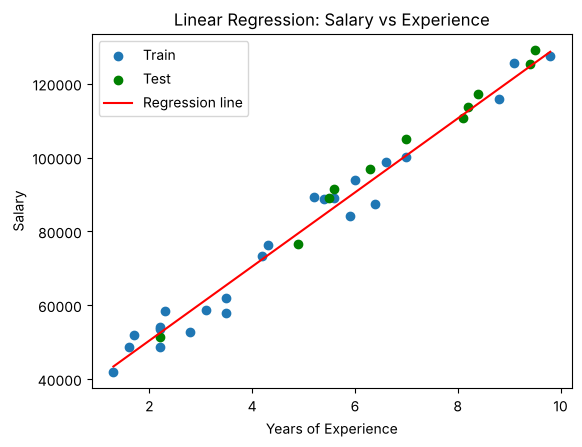

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

rs = np.random.default_rng(11)
n = 35
exp_years = np.sort(np.round(rs.uniform(1, 10, n), 1))
salary = np.round(30000 + 10200 * exp_years + rs.normal(0, 4500, n), 0)
data = pd.DataFrame({"YearsExperience": exp_years, "Salary": salary})
print(data.head())

X = data[["YearsExperience"]]
y = data["Salary"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)
print("Train size:", len(X_train), "| Test size:", len(X_test))

lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

print(f"Slope (coefficient): {lin_reg.coef_[0]:,.2f}   -> salary rises by this much per extra year")
print(f"Intercept           : {lin_reg.intercept_:,.2f}")
print(f"Equation            : Salary = {lin_reg.intercept_:,.2f} + {lin_reg.coef_[0]:,.2f} x Experience")

y_pred = lin_reg.predict(X_test)
result_df = pd.DataFrame({"Experience": X_test["YearsExperience"].values,
                           "Actual": y_test.values,
                           "Predicted": y_pred.round(0)})
print(result_df)

mse = mean_squared_error(y_test, y_pred)
print(f"MSE  : {mse:,.2f}")
print(f"RMSE : {np.sqrt(mse):,.2f}")
print(f"R²   : {r2_score(y_test, y_pred):.4f}")

new = pd.DataFrame({"YearsExperience": [8.0]})
print(f"Predicted salary for 8.0 years of experience: {lin_reg.predict(new)[0]:,.0f}")

plt.scatter(X_train, y_train, label="Train")
plt.scatter(X_test, y_test, color="green", label="Test")
plt.plot(X, lin_reg.predict(X), color="red", label="Regression line")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Linear Regression: Salary vs Experience")
plt.legend()
plt.show()